# 🎡 Lucky or Rigged? Testing Fairness in Roulette with Simulation




## Part A: The Game

Choose a bet (Red, Black, Odd, Even or one number from 0 to 36), set the stake and press **SPIN**.


In [1]:
!pip -q install ipywidgets
from google.colab import output
output.enable_custom_widget_manager()

import random
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Keep existing state if this cell is accidentally rerun in the same runtime.
if "_roulette_state" not in globals():
    _roulette_state = {
        "balance": 1000,
        "spin_count": 0,
        "history": []
    }

state = _roulette_state
RED_NUMBERS = {1, 3, 5, 7, 9, 12, 14, 16, 18,
               19, 21, 23, 25, 27, 30, 32, 34, 36}

def number_color(n):
    if n == 0:
        return "Green"
    return "Red" if n in RED_NUMBERS else "Black"

title = widgets.HTML(value="""
<div style="background:#163b2b;color:white;padding:16px;border-radius:12px;">
<h2 style="margin:0;">🎡 Interactive Roulette</h2>
<p style="margin:6px 0 0;">Choose a bet, then press SPIN as many times as you want.</p>
</div>""")
balance_display = widgets.HTML()
bet_type = widgets.Dropdown(
    options=[("Red", "Red"), ("Black", "Black"), ("Odd", "Odd"),
             ("Even", "Even"), ("Exact Number (0–36)", "Number")],
    value="Red", description="Bet:", style={"description_width": "initial"}
)
bet_amount = widgets.IntSlider(
    value=10, min=1, max=100, step=1, description="Stake:",
    style={"description_width": "initial"}, continuous_update=False,
    layout=widgets.Layout(width="340px")
)
chosen_number = widgets.BoundedIntText(
    value=17, min=0, max=36, description="Number:",
    style={"description_width": "initial"}
)
number_row = widgets.HBox([chosen_number])
spin_button = widgets.Button(
    description="🎯 SPIN", button_style="success",
    layout=widgets.Layout(width="150px", height="44px")
)
reset_button = widgets.Button(
    description="Reset to 1000", button_style="warning",
    layout=widgets.Layout(width="150px", height="44px")
)
result_display = widgets.Output()
history_display = widgets.Output()

def update_balance():
    balance_display.value = f"""
    <div style="padding:12px;background:#f0f7f2;border-radius:10px;margin:10px 0;">
      <b>Current balance:</b>
      <span style="font-size:24px;color:#176b3a;">{state['balance']} coins</span>
      &nbsp; | &nbsp; <b>Total spins:</b> {state['spin_count']}
    </div>"""

def update_number_visibility(change=None):
    number_row.layout.display = "flex" if bet_type.value == "Number" else "none"

def show_history():
    with history_display:
        clear_output(wait=True)
        if not state["history"]:
            display(HTML("<p>No spins yet. Your results will appear here.</p>"))
            return
        rows = ""
        for item in reversed(state["history"][-10:]):
            color_code = {"Red": "#c62828", "Black": "#222", "Green": "#16803c"}[item["color"]]
            net_color = "#16803c" if item["net"] > 0 else "#c62828"
            rows += (
                f"<tr><td>{item['spin']}</td>"
                f"<td style='color:{color_code};font-weight:bold'>{item['number']} ({item['color']})</td>"
                f"<td>{item['bet']}</td><td>{item['stake']}</td>"
                f"<td style='color:{net_color}'>{item['net']:+}</td>"
                f"<td>{item['balance']}</td></tr>"
            )
        display(HTML(
            "<h3>Recent spins (latest 10)</h3>"
            "<table border='1' cellpadding='7' style='border-collapse:collapse;width:100%'>"
            "<tr><th>Spin</th><th>Result</th><th>Your bet</th><th>Stake</th>"
            "<th>Net change</th><th>Balance after spin</th></tr>" + rows + "</table>"
        ))

def do_spin(_):
    balance = state["balance"]
    stake = bet_amount.value
    selected_bet = bet_type.value
    picked = chosen_number.value

    with result_display:
        clear_output(wait=True)
        if balance <= 0:
            display(HTML("<h3 style='color:#c62828'>No coins left. Press Reset to start a new game.</h3>"))
            return
        if stake > balance:
            display(HTML(f"<h3 style='color:#c62828'>You have {balance} coins, but selected a {stake}-coin bet. Lower your stake.</h3>"))
            return

        result = random.randint(0, 36)
        color = number_color(result)
        if selected_bet == "Number":
            won = result == picked
            net = stake * 35 if won else -stake
            bet_label = f"Number {picked}"
        elif selected_bet in ("Red", "Black"):
            won = color == selected_bet
            net = stake if won else -stake
            bet_label = selected_bet
        elif selected_bet == "Odd":
            won = result != 0 and result % 2 == 1
            net = stake if won else -stake
            bet_label = "Odd"
        else:
            won = result != 0 and result % 2 == 0
            net = stake if won else -stake
            bet_label = "Even"

        # Update shared state so the NEXT spin starts from this new balance.
        state["balance"] = balance + net
        state["spin_count"] += 1
        state["history"].append({
            "spin": state["spin_count"], "number": result, "color": color,
            "bet": bet_label, "stake": stake, "net": net,
            "balance": state["balance"]
        })

        color_code = {"Red": "#c62828", "Black": "#222", "Green": "#16803c"}[color]
        outcome_color = "#16803c" if won else "#c62828"
        outcome = "YOU WIN!" if won else "YOU LOSE!"
        display(HTML(f"""
        <div style="border:2px solid {outcome_color};padding:16px;border-radius:12px;">
          <h2 style="color:{outcome_color};margin-top:0;">{outcome}</h2>
          <p style="font-size:20px;">Wheel result:
          <span style="background:{color_code};color:white;padding:8px 14px;border-radius:8px;font-weight:bold">{result}</span>
          <b>{color}</b></p>
          <p>Your bet: <b>{bet_label}</b> | Stake: <b>{stake} coins</b></p>
          <p>Net change: <b style="color:{outcome_color}">{net:+} coins</b></p>
          <p>Updated balance: <b>{state['balance']} coins</b></p>
        </div>"""))

    update_balance()
    show_history()

def reset_game(_):
    state["balance"] = 1000
    state["spin_count"] = 0
    state["history"].clear()
    update_balance()
    with result_display:
        clear_output(wait=True)
        display(HTML("<p>Game reset. Balance is now 1000 coins.</p>"))
    show_history()

bet_type.observe(update_number_visibility, names="value")
spin_button.on_click(do_spin)
reset_button.on_click(reset_game)
update_balance()
update_number_visibility()
show_history()

display(title)
display(balance_display)
display(widgets.VBox([
    bet_type, number_row, bet_amount,
    widgets.HBox([spin_button, reset_button])
]))
display(result_display)
display(history_display)
display(HTML("""
<p style="color:#555;font-size:13px;">
Red/Black/Odd/Even pay 1:1 profit. Exact number pays 35:1 profit.
Zero is green and loses Red/Black/Odd/Even bets. All coins are virtual.
</p>"""))

HTML(value='\n<div style="background:#163b2b;color:white;padding:16px;border-radius:12px;">\n<h2 style="margin…

HTML(value='\n    <div style="padding:12px;background:#f0f7f2;border-radius:10px;margin:10px 0;">\n      <b>Cu…

Output()

Output()


## Part 1: Simulating 100,000 Spins

**What we expect:** if the wheel is fair, every number should come up about the same number of times: 100,000 / 37 ≈ 2,703 times.

In [2]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Which numbers are red on a roulette wheel
RED = {1, 3, 5, 7, 9, 12, 14, 16, 18, 19, 21, 23, 25, 27, 30, 32, 34, 36}
IS_RED = np.isin(np.arange(37), list(RED))      # True for red numbers

np.random.seed(42)
N = 100_000
spins = np.random.randint(0, 37, N)             # 100,000 spins

print("First 15 spins:", spins[:15])

First 15 spins: [28 14  7 20 18 22 10 10 23 35 23  2 21  1 23]


In [3]:
# Basic statistics
print("Mean   :", round(np.mean(spins), 2), "  (fair wheel: 18)")
print("Median :", np.median(spins))
print("Std    :", round(np.std(spins), 2), "  (fair wheel: about 10.68)")
print("Min / Max:", np.min(spins), "/", np.max(spins))

counts = np.bincount(spins, minlength=37)       # how many times each number came up
print("\nExpected times per number:", round(N / 37))
print("Most frequent number:", np.argmax(counts), "->", counts.max(), "times")
print("Least frequent number:", np.argmin(counts), "->", counts.min(), "times")

Mean   : 18.03   (fair wheel: 18)
Median : 18.0
Std    : 10.66   (fair wheel: about 10.68)
Min / Max: 0 / 36

Expected times per number: 2703
Most frequent number: 22 -> 2819 times
Least frequent number: 5 -> 2575 times


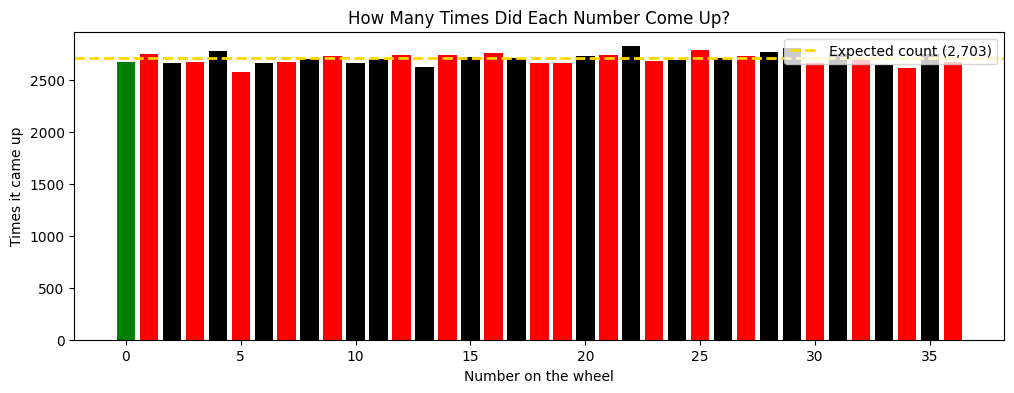

In [4]:
# Bar chart: how often did each number come up?
colors = ["green" if n == 0 else ("red" if IS_RED[n] else "black") for n in range(37)]

plt.figure(figsize=(12, 4))
plt.bar(range(37), counts, color=colors)
plt.axhline(N / 37, color="gold", linestyle="--", linewidth=2, label="Expected count (2,703)")
plt.title("How Many Times Did Each Number Come Up?")
plt.xlabel("Number on the wheel")
plt.ylabel("Times it came up")
plt.legend()
plt.show()

**Result:** the mean is about 18, the median is 18, and all bars are close to the gold line. The wheel *looks* fair.
But "looks fair" is not proof. Are the small differences just luck? Part 2 answers this with a proper test.

---
## Part 2: Chi-Square Test, Is the Wheel Fair?

**Idea:** the chi-square test compares what we **observed** with what we **expected**.

- **H₀ (null hypothesis):** the wheel is fair.
- **H₁:** the wheel is not fair.
- We use a 5% significance level (α = 0.05).

$$\chi^2 = \sum \frac{(\text{Observed} - \text{Expected})^2}{\text{Expected}}$$

**Rule:** if χ² is bigger than the **critical value** (or p-value < 0.05), we **reject H₀**: there is evidence the wheel is not fair.

In [5]:
def chi_square_test(observed):
    expected = np.full(37, observed.sum() / 37)               # fair wheel: all numbers equal
    chi2 = np.sum((observed - expected) ** 2 / expected)
    critical = stats.chi2.ppf(0.95, 36)                       # 36 = 37 numbers - 1
    p_value = stats.chi2.sf(chi2, 36)
    return chi2, critical, p_value

chi2, critical, p = chi_square_test(counts)
print("Chi-square value:", round(chi2, 2))
print("Critical value  :", round(critical, 2))
print("p-value         :", round(p, 3))

if chi2 > critical:
    print("Result: Reject H0 -> the wheel is NOT fair")
else:
    print("Result: Fail to reject H0 -> the wheel is FAIR")

Chi-square value: 38.22
Critical value  : 51.0
p-value         : 0.369
Result: Fail to reject H0 -> the wheel is FAIR


### Can the test catch a cheating wheel?
We make a rigged wheel where 0 comes up 3.5% of the time instead of 2.7%, and run the same test.

Chi-square value: 279.99   Critical value: 51.0
Result: Reject H0 -> the wheel is RIGGED!


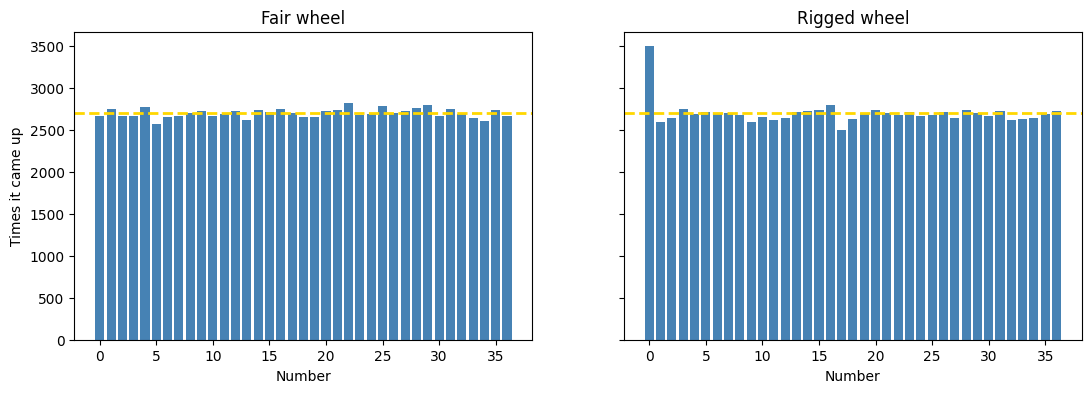

In [6]:
np.random.seed(123)
prob = np.full(37, (1 - 0.035) / 36)
prob[0] = 0.035                                               # rigged zero
rigged_spins = np.random.choice(37, size=N, p=prob)
rigged_counts = np.bincount(rigged_spins, minlength=37)

chi2_r, critical_r, p_r = chi_square_test(rigged_counts)
print("Chi-square value:", round(chi2_r, 2), "  Critical value:", round(critical_r, 2))
print("Result:", "Reject H0 -> the wheel is RIGGED!" if chi2_r > critical_r else "Fail to reject H0")

# Compare the two wheels
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, c, name in zip(axes, [counts, rigged_counts], ["Fair wheel", "Rigged wheel"]):
    ax.bar(range(37), c, color="steelblue")
    ax.axhline(N / 37, color="gold", linestyle="--", linewidth=2)
    ax.set_title(name)
    ax.set_xlabel("Number")
axes[0].set_ylabel("Times it came up")
plt.show()

**Result:** the honest wheel passes the test (χ² below critical value). The rigged wheel **fails** it (χ² is far above). So chi-square can catch a cheating casino, even for a small change.

---
## Part 3: t-Test, Does a Red Bet Win or Lose?

**Idea:** a player bets **1 coin on Red** every spin. Each spin the result is **+1** (red) or **−1** (black or green).

- **H₀:** the average result per spin is **0** (a fair game, no one wins or loses on average).
- **H₁:** the average result per spin is **not 0**.

**Why we expect a loss:** there are 18 red numbers out of 37, so P(win) = 18/37 = 48.6%, not 50%. The green zero takes the difference.
The average result should be about **−1/37 ≈ −0.027 coins per spin**. This is called the **house edge**.

In [7]:
red_result = np.where(IS_RED[spins], 1, -1)       # +1 if red, -1 otherwise

mean_result = red_result.mean()
t_stat, p_value = stats.ttest_1samp(red_result, 0)

print("Average result per spin:", round(mean_result, 4))
print("Theory (house edge)    :", round(-1 / 37, 4))
print("t-statistic            :", round(t_stat, 2))
print("p-value                :", p_value)

if p_value < 0.05:
    print("Result: Reject H0 -> the player loses money on average")
else:
    print("Result: Fail to reject H0")

Average result per spin: -0.03
Theory (house edge)    : -0.027
t-statistic            : -9.5
p-value                : 2.067791697230852e-21
Result: Reject H0 -> the player loses money on average


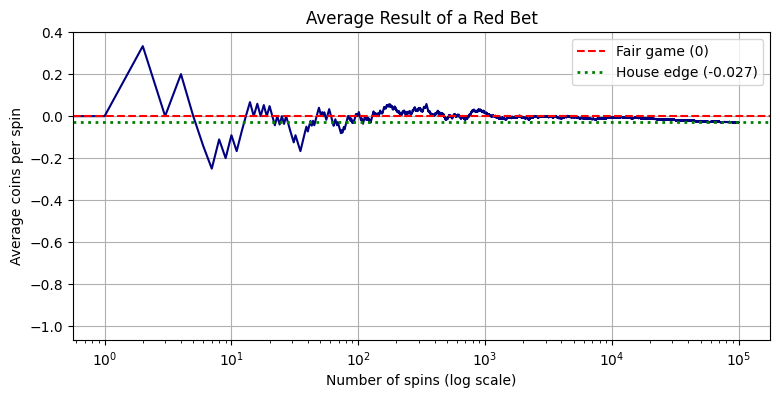

In [8]:
# Running average: how the average result changes as we play more spins
running_avg = np.cumsum(red_result) / np.arange(1, N + 1)

plt.figure(figsize=(9, 4))
plt.plot(running_avg, color="navy")
plt.axhline(0, color="red", linestyle="--", label="Fair game (0)")
plt.axhline(-1 / 37, color="green", linestyle=":", linewidth=2, label="House edge (-0.027)")
plt.xscale("log")
plt.title("Average Result of a Red Bet")
plt.xlabel("Number of spins (log scale)")
plt.ylabel("Average coins per spin")
plt.legend()
plt.grid(True)
plt.show()

**Result:** p-value is almost 0, so we reject H₀. The player really does lose about 2.7 paisa of every taka bet.
In the graph, the average jumps around at the start (luck), but with more spins it settles below 0, close to the house edge.

---
## Part 4: 3D Animation, The Ball Spiralling into a Pocket


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Video, Image, display

# ---- Wheel setup (age onno cell e chilo, ekhane joga korlam) ----
RED_SET = {1, 3, 5, 7, 9, 12, 14, 16, 18, 19, 21, 23, 25, 27, 30, 32, 34, 36}

def color_of(n):
    if n == 0:
        return "Green"
    return "Red" if n in RED_SET else "Black"

POCKET_COLORS = ["green" if n == 0 else ("red" if n in RED_SET else "black") for n in range(37)]

# Real European wheel order (clockwise)
WHEEL = [0, 32, 15, 19, 4, 21, 2, 25, 17, 34, 6, 27, 13, 36, 11, 30, 8, 23, 10, 5, 24, 16, 33, 1, 20,
         14, 31, 9, 22, 18, 29, 7, 28, 12, 35, 3, 26]

np.random.seed(5)
winner = int(np.random.randint(0, 37))                   # the number this animation lands on
target_angle = 2 * np.pi * WHEEL.index(winner) / 37

frames = 90
t = np.linspace(0, 1, frames)
theta = target_angle + 2 * np.pi * 4 * (1 - t) ** 1.5    # ball slows down and stops at the pocket
radius = 3 + 2 * (1 - t) ** 2                            # spirals inward from 5 to 3
height = 1.0 * (1 - t) ** 2                              # drops down to the wheel

ball_x = radius * np.cos(theta)
ball_y = radius * np.sin(theta)
ball_z = height

# pocket positions on the wheel
pocket_angles = 2 * np.pi * np.arange(37) / 37
px, py = 3 * np.cos(pocket_angles), 3 * np.sin(pocket_angles)
pcolors = [POCKET_COLORS[n] for n in WHEEL]

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="3d")

def update_plot(i):
    ax.clear()
    ax.scatter(px, py, np.zeros(37), c=pcolors, s=60, depthshade=False)               # the pockets
    ax.plot(ball_x[:i + 1], ball_y[:i + 1], ball_z[:i + 1], color="gold", alpha=0.7)  # ball trail
    ax.scatter(ball_x[i], ball_y[i], ball_z[i], color="blue", s=160)                  # the ball
    ax.set_xlim(-5.5, 5.5)
    ax.set_ylim(-5.5, 5.5)
    ax.set_zlim(0, 2)
    ax.set_xlabel("X-axis")
    ax.set_ylabel("Y-axis")
    ax.set_zlabel("Z-axis")
    if i == frames - 1:
        ax.set_title(f"Ball landed on {winner} ({color_of(winner)})")
    else:
        ax.set_title("3D Roulette Ball Animation")

ani = animation.FuncAnimation(fig, update_plot, frames=frames, interval=60)

try:
    ani.save("roulette_3d.mp4", writer="ffmpeg", fps=20)
    plt.close(fig)
    display(Video("roulette_3d.mp4", embed=True))
except Exception as e:
    print("ffmpeg not available, saving as GIF instead:", e)
    ani.save("roulette_3d.gif", writer="pillow", fps=20)
    plt.close(fig)
    display(Image("roulette_3d.gif"))
print(f"The ball lands on {winner} ({color_of(winner)})")

The ball lands on 35 (Black)



## Final Conclusion
Roulette looks like a fair random game, but the green zero gives the casino a small edge, and over many spins the casino wins in the long run.

